# 02. YOLO26s: реальные и синтетические изображения

Датасет `data`, класс `particle`. Сравнение пяти вариантов обучения из исходных весов.
Выбор модели — по val mAP50–95, затем оценка на test.


In [13]:
from pathlib import Path
from errno import EACCES, EINVAL
from time import sleep
import gc
import math
import shutil

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import torch
from ultralytics import YOLO
from ultralytics.models.yolo.detect import DetectionTrainer
import yaml

ROOT = Path.cwd().resolve()
if ROOT.name == 'research':
    ROOT = ROOT.parent

DATA = ROOT / 'data'
DATASET = 'mixed'
IMAGES = DATA / 'images'
LABELS = DATA / 'labels'
CONFIG = DATA / 'dataset.yaml'
MODELS = ROOT / 'models'
COMPARISON = MODELS / 'comparison.csv'
CHECKPOINT = ROOT / 'research/yolo26s.pt'

SPLIT_GROUPS = {'train': ['D03', 'D04'], 'val': ['D01', 'D02'], 'test': ['D05']}
CLASSES = (DATA / 'classes.txt').read_text(encoding='utf-8').splitlines()
IMAGE_EXTENSIONS = {'.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff'}

EPOCHS = 50
PATIENCE = 20
IMAGE_SIZE = 1024
EVAL_IMAGE_SIZE = 1024  # Единый размер для итогового сравнения.
BATCH_SIZE = 4
DEVICE = None
SEED = 42
CONFIDENCE = 0.25  # Порог для подсчёта и визуализации.
MAX_DETECTIONS = 1000


## 1. Разделение данных

Train — D03/D04, val — D01/D02, test — D05. Синтетика добавляется только в train.


In [14]:
group_to_split = {group: split for split, groups in SPLIT_GROUPS.items() for group in groups}
group_to_split['SYN'] = 'train'
images = sorted(p for p in IMAGES.rglob('*') if p.suffix.lower() in IMAGE_EXTENSIONS)

plans = []
for source_image in images:
    source_label = LABELS / source_image.relative_to(IMAGES).with_suffix('.txt')
    group = source_image.stem.split('_', 1)[0]
    split = group_to_split[group]
    image_path = IMAGES / split / source_image.name
    label_path = LABELS / split / source_label.name
    for source, target in [(source_image, image_path), (source_label, label_path)]:
        if source != target and target.exists():
            raise FileExistsError(target)
    objects = len(source_label.read_text(encoding='utf-8-sig').splitlines())
    plans.append({'source_image': source_image, 'source_label': source_label,
        'image': image_path, 'label': label_path, 'split': split, 'group': group, 'objects': objects})

for plan in plans:
    for kind in ('image', 'label'):
        source, target = plan[f'source_{kind}'], plan[kind]
        if source != target:
            target.parent.mkdir(parents=True, exist_ok=True)
            shutil.move(str(source), str(target))

config = {'path': DATA.as_posix(), 'train': 'images/train', 'val': 'images/val',
          'test': 'images/test', 'names': dict(enumerate(CLASSES))}
CONFIG.write_text(yaml.safe_dump(config, allow_unicode=True, sort_keys=False), encoding='utf-8')
display(pd.DataFrame(plans).groupby(['split', 'group']).agg(images=('image', 'count'), objects=('objects', 'sum')))


images  objects
split group                 
test  D05         3      109
train D03        15      720
      D04         9      665
      SYN        12      135
val   D01         2       92
      D02         2      145

## 2. Варианты обучения

| Вариант | Параметры |
|---|---|
| baseline | `optimizer=auto` |
| adamw | `lr0=0.0003`, `momentum=0.9`, `warmup_bias_lr=0` |
| adamw_freeze10 | adamw + `freeze=10` |
| adamw_nbs16 | adamw + `nbs=16` |
| adamw_1280 | adamw + `imgsz=1280` |

Список запусков — `ACTIVE_EXPERIMENTS`. Последние три варианта сравниваются с `adamw`.
Seed, batch, число эпох и аугментации одинаковы. Оценка всех моделей — при `EVAL_IMAGE_SIZE=1024`.
Число шагов за эпоху зависит от размера train.
[Параметры Ultralytics](https://docs.ultralytics.com/modes/train/).


In [15]:
if DEVICE is None:
    DEVICE = 0 if torch.cuda.is_available() else 'cpu'

TRAIN_ARGS = dict(
    data=str(CONFIG.resolve()), epochs=EPOCHS, patience=PATIENCE,
    imgsz=IMAGE_SIZE, batch=BATCH_SIZE, device=DEVICE, workers=0,
    seed=SEED, deterministic=True, optimizer='auto', pretrained=True,
    project=str(MODELS), exist_ok=False, save=True, plots=False,
    cache=False, val=True, max_det=MAX_DETECTIONS,
    hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, degrees=10.0, translate=0.05,
    scale=0.15, fliplr=0.5, flipud=0.5, mosaic=0.0, mixup=0.0, close_mosaic=0,
)
ADAMW = dict(optimizer='AdamW', lr0=0.0003, momentum=0.9, warmup_bias_lr=0.0)
EXPERIMENTS = {
    'baseline': {},
    'adamw': ADAMW,
    'adamw_freeze10': {**ADAMW, 'freeze': 10},
    'adamw_nbs16': {**ADAMW, 'nbs': 16},
    'adamw_1280': {**ADAMW, 'imgsz': 1280},
}
ACTIVE_EXPERIMENTS = list(EXPERIMENTS)
print('Устройство:', DEVICE)
display(pd.DataFrame([
    {'experiment': name, 'imgsz': IMAGE_SIZE, 'freeze': 0, 'nbs': 64,
     'optimizer': 'auto', **EXPERIMENTS[name]}
    for name in ACTIVE_EXPERIMENTS
]).set_index('experiment').fillna('auto'))


Устройство: 0


,imgsz,freeze,nbs,optimizer,lr0,momentum,warmup_bias_lr
experiment,,,,,,,
baseline,1024,0,64,auto,auto,auto,auto
adamw,1024,0,64,AdamW,0.0003,0.9,0.0
adamw_freeze10,1024,10,64,AdamW,0.0003,0.9,0.0
adamw_nbs16,1024,0,16,AdamW,0.0003,0.9,0.0
adamw_1280,1280,0,64,AdamW,0.0003,0.9,0.0


## 3. Обучение

Каждый вариант обучается из `yolo26s.pt`. Сохраняются веса, параметры и история обучения.
Результаты оценки — `models/comparison.csv`.
MAE показывает ошибку подсчёта при `conf=0.25`; precision и recall берутся из отчёта YOLO.


In [16]:
# Повтор сохранения при временном сбое доступа к файлу весов.
class CheckpointTrainer(DetectionTrainer):
    def save_model(self):
        for attempt in range(5):
            try:
                return super().save_model()
            except OSError as error:
                if error.errno not in (EACCES, EINVAL) or attempt == 4:
                    raise
                sleep(0.5 * (attempt + 1))


def evaluate(detector, run_dir, split):
    metrics = detector.val(
        data=str(CONFIG.resolve()), split=split, imgsz=EVAL_IMAGE_SIZE,
        batch=BATCH_SIZE, device=DEVICE, workers=0, conf=0.001, iou=0.7,
        max_det=MAX_DETECTIONS, rect=True, augment=False, half=False,
        plots=False, save_json=False, save_txt=False,
        project=str(run_dir.parent), name=run_dir.name, exist_ok=True,
    )
    values = {
        f'{split}_precision': float(metrics.box.mp),
        f'{split}_recall': float(metrics.box.mr),
        f'{split}_map50': float(metrics.box.map50),
        f'{split}_map50_95': float(metrics.box.map),
    }
    counts = []
    for plan in (p for p in plans if p['split'] == split):
        result = detector.predict(
            source=str(plan['image']), imgsz=EVAL_IMAGE_SIZE,
            conf=CONFIDENCE, iou=0.7, max_det=MAX_DETECTIONS, device=DEVICE,
            rect=True, augment=False, half=False, save=False, save_txt=False, verbose=False,
        )[0]
        predicted = len(result.boxes)
        counts.append({'image': plan['image'].stem, 'labels': plan['objects'],
                       'predicted': predicted, 'absolute_error': abs(predicted - plan['objects'])})
    counts = pd.DataFrame(counts)
    values[f'{split}_count_mae'] = float(counts['absolute_error'].mean())
    return values, counts


def save_comparison(row):
    table = pd.read_csv(COMPARISON) if COMPARISON.exists() else pd.DataFrame()
    if not table.empty:
        table = table.loc[table['run_dir'] != row['run_dir']]
    table = pd.concat([table, pd.DataFrame([row])], ignore_index=True)
    table.to_csv(COMPARISON, index=False)


runs = []
for name in ACTIVE_EXPERIMENTS:
    args = {**TRAIN_ARGS, **EXPERIMENTS[name], 'name': f'{DATASET}_{name}'}
    model = YOLO(str(CHECKPOINT), task='detect')
    model.train(trainer=CheckpointTrainer, **args)
    run_dir = Path(model.trainer.save_dir)
    best = run_dir / 'weights/best.pt'
    history = pd.read_csv(run_dir / 'results.csv')
    history.columns = history.columns.str.strip()
    row = {
        'dataset': DATASET, 'experiment': name, 'seed': SEED,
        'train_images': sum(p['split'] == 'train' for p in plans),
        'train_imgsz': args['imgsz'], 'eval_imgsz': EVAL_IMAGE_SIZE,
        'batch': BATCH_SIZE, 'count_conf': CONFIDENCE, 'max_det': MAX_DETECTIONS,
        'epochs_limit': EPOCHS, 'patience': PATIENCE, 'epochs_completed': len(history),
        'peak_epoch': int(history.loc[history['metrics/mAP50-95(B)'].idxmax(), 'epoch']),
        'optimizer': args['optimizer'], 'lr0': args.get('lr0', 'auto'),
        'freeze': args.get('freeze', 0), 'nbs': args.get('nbs', 64),
        'run_dir': run_dir.relative_to(ROOT).as_posix(),
        'weights': best.relative_to(ROOT).as_posix(),
    }
    del model
    gc.collect()
    torch.cuda.empty_cache()

    detector = YOLO(str(best), task='detect')
    values, counts = evaluate(detector, run_dir, 'val')
    row.update(values)
    runs.append(row)
    save_comparison(row)
    display(pd.DataFrame([row])[['experiment', 'val_map50', 'val_map50_95', 'val_count_mae']])
    del detector
    gc.collect()
    torch.cuda.empty_cache()


New https://pypi.org/project/ultralytics/8.4.177 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.24  Python-3.10.6 torch-2.9.1+cu128 CUDA:0 (NVIDIA GeForce RTX 5070, 12227MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=0, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\games\!!!studyMaga\2026\PP_Particles\PP_Particles\data\dataset.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=1024, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=1000, mixup=0.0, mode=train, model=C:\games\!!!studyMaga\2026

,experiment,val_map50,val_map50_95,val_count_mae
0,baseline,0.732778,0.467307,17.0


New https://pypi.org/project/ultralytics/8.4.177 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.24  Python-3.10.6 torch-2.9.1+cu128 CUDA:0 (NVIDIA GeForce RTX 5070, 12227MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=0, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\games\!!!studyMaga\2026\PP_Particles\PP_Particles\data\dataset.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=1024, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0003, lrf=0.01, mask_ratio=4, max_det=1000, mixup=0.0, mode=train, model=C:\games\!!!studyMaga\20

,experiment,val_map50,val_map50_95,val_count_mae
0,adamw,0.33013,0.17037,49.0


New https://pypi.org/project/ultralytics/8.4.177 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.24  Python-3.10.6 torch-2.9.1+cu128 CUDA:0 (NVIDIA GeForce RTX 5070, 12227MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=0, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\games\!!!studyMaga\2026\PP_Particles\PP_Particles\data\dataset.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=10, half=False, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=1024, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0003, lrf=0.01, mask_ratio=4, max_det=1000, mixup=0.0, mode=train, model=C:\games\!!!studyMaga\2026

,experiment,val_map50,val_map50_95,val_count_mae
0,adamw_freeze10,0.345653,0.218551,26.5


New https://pypi.org/project/ultralytics/8.4.177 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.24  Python-3.10.6 torch-2.9.1+cu128 CUDA:0 (NVIDIA GeForce RTX 5070, 12227MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=0, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\games\!!!studyMaga\2026\PP_Particles\PP_Particles\data\dataset.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=1024, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0003, lrf=0.01, mask_ratio=4, max_det=1000, mixup=0.0, mode=train, model=C:\games\!!!studyMaga\20

,experiment,val_map50,val_map50_95,val_count_mae
0,adamw_nbs16,0.720352,0.473522,13.0


New https://pypi.org/project/ultralytics/8.4.177 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.24  Python-3.10.6 torch-2.9.1+cu128 CUDA:0 (NVIDIA GeForce RTX 5070, 12227MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=0, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\games\!!!studyMaga\2026\PP_Particles\PP_Particles\data\dataset.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=1280, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0003, lrf=0.01, mask_ratio=4, max_det=1000, mixup=0.0, mode=train, model=C:\games\!!!studyMaga\20

,experiment,val_map50,val_map50_95,val_count_mae
0,adamw_1280,0.059227,0.034395,30.5


## 4. Сравнение на val

Метрики рассчитываются с общими настройками. Модель для просмотра выбирается по val mAP50–95.
Кривые показывают результаты validation во время обучения.


,experiment,peak_epoch,val_precision,val_recall,val_map50,val_map50_95,val_count_mae,weights
3,adamw_nbs16,39,0.7145,0.6287,0.7204,0.4735,13.0,models/mixed_adamw_nbs16/weights/best.pt
0,baseline,31,0.6784,0.6676,0.7328,0.4673,17.0,models/mixed_baseline/weights/best.pt
2,adamw_freeze10,33,0.3000,0.4346,0.3457,0.2186,26.5,models/mixed_adamw_freeze10/weights/best.pt
1,adamw,7,0.3689,0.3544,0.3301,0.1704,49.0,models/mixed_adamw/weights/best.pt
4,adamw_1280,22,0.0527,0.2447,0.0592,0.0344,30.5,models/mixed_adamw_1280/weights/best.pt


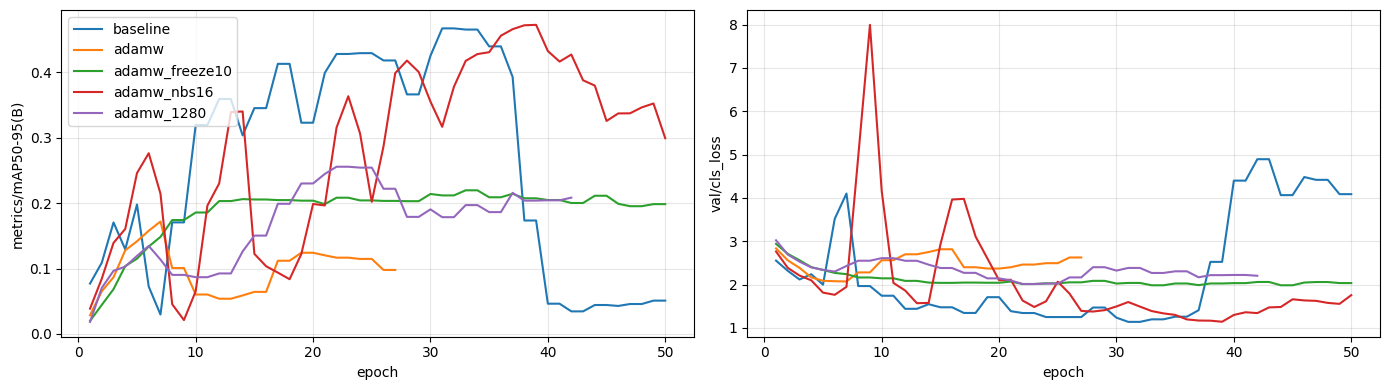

Выбор по val: adamw_nbs16 | models/mixed_adamw_nbs16/weights/best.pt


In [17]:
ranking = pd.DataFrame(runs).sort_values('val_map50_95', ascending=False)
display(ranking[['experiment', 'peak_epoch', 'val_precision', 'val_recall',
                 'val_map50', 'val_map50_95', 'val_count_mae', 'weights']].round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for run in runs:
    history = pd.read_csv(ROOT / run['run_dir'] / 'results.csv')
    history.columns = history.columns.str.strip()
    for ax, column in zip(axes, ['metrics/mAP50-95(B)', 'val/cls_loss']):
        ax.plot(history['epoch'], history[column], label=run['experiment'])
        ax.set(xlabel='epoch', ylabel=column)
        ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()

selected = ranking.iloc[0]
print('Выбор по val:', selected['experiment'], '|', selected['weights'])


## 5. Предсказания на val

Рамки выбранной модели и число частиц по кадрам.


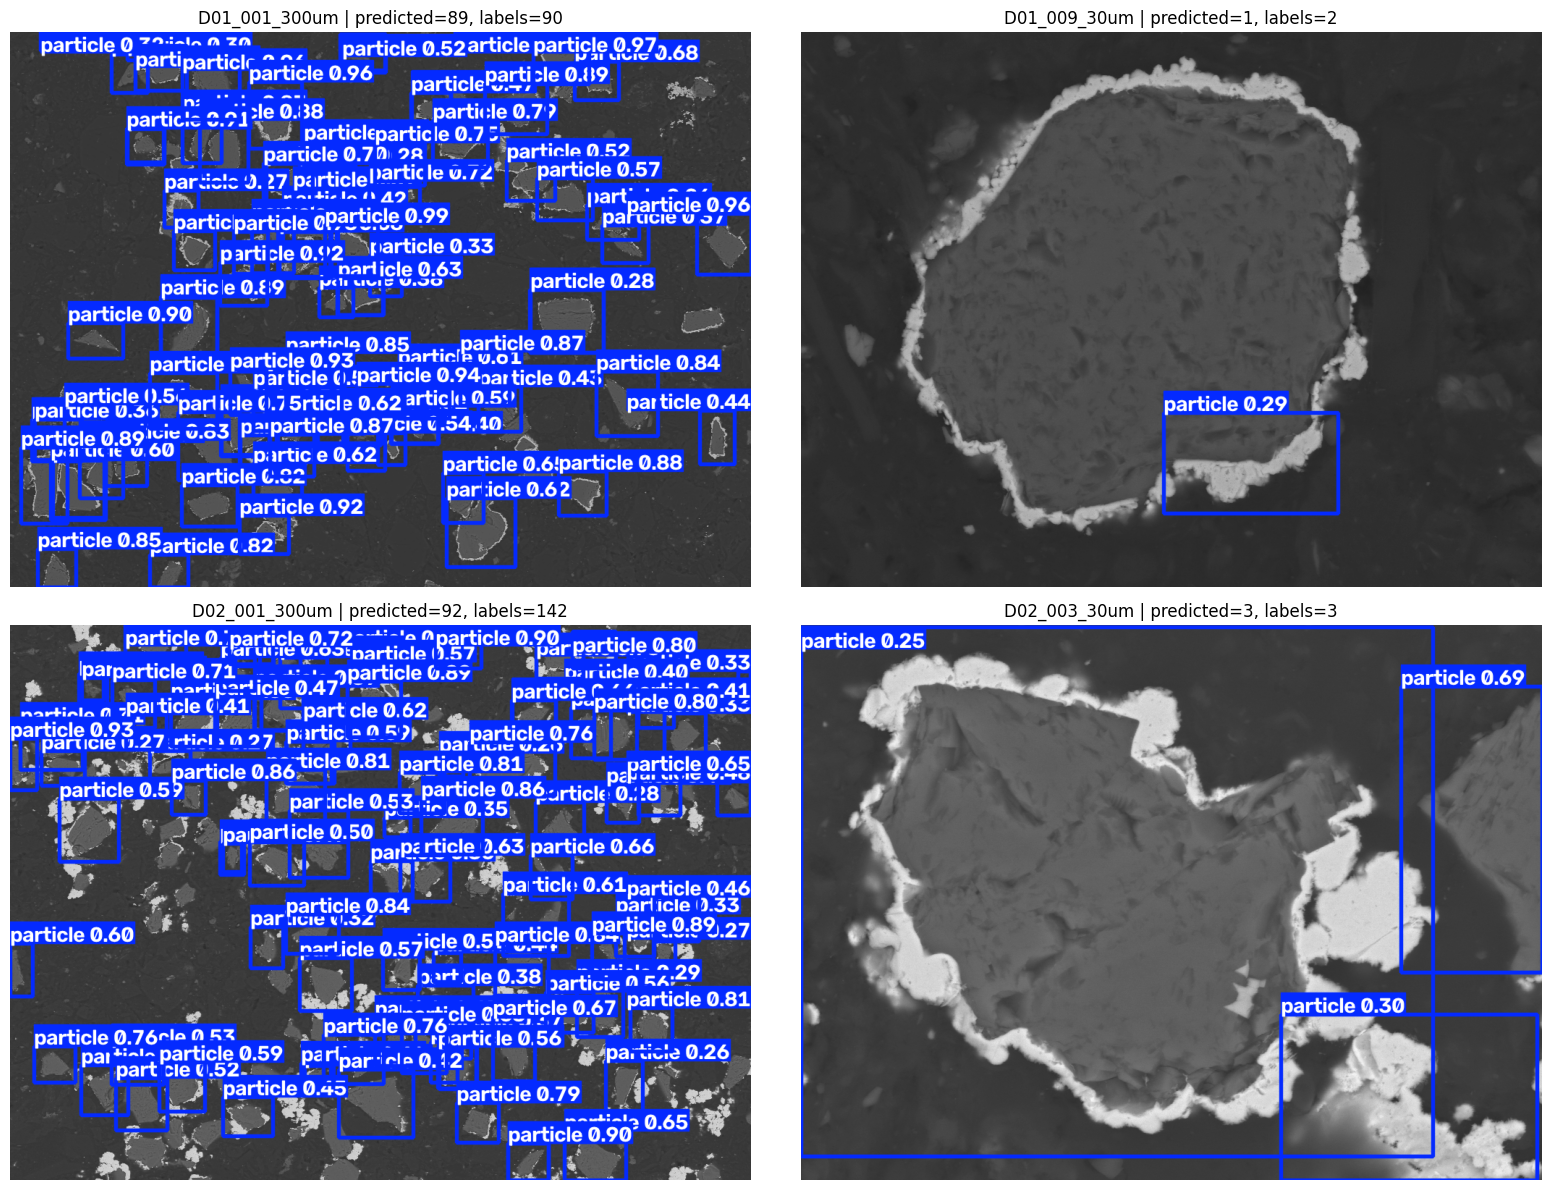

In [18]:
detector = YOLO(str(ROOT / selected['weights']), task='detect')
preview = [p for p in plans if p['split'] == 'val']
fig, axes = plt.subplots(math.ceil(len(preview) / 2), 2, figsize=(16, 6 * math.ceil(len(preview) / 2)), squeeze=False)
for ax, plan in zip(axes.flat, preview):
    result = detector.predict(
        source=str(plan['image']), imgsz=EVAL_IMAGE_SIZE, conf=CONFIDENCE,
        iou=0.7, max_det=MAX_DETECTIONS, device=DEVICE, rect=True, augment=False,
        half=False, save=False, save_txt=False, verbose=False,
    )[0]
    ax.imshow(result.plot()[:, :, ::-1])
    ax.set_title(f"{plan['image'].stem} | predicted={len(result.boxes)}, labels={plan['objects']}")
    ax.axis('off')
for ax in list(axes.flat)[len(preview):]:
    ax.axis('off')
plt.tight_layout()
plt.show()
del detector
gc.collect()
torch.cuda.empty_cache()


## 6. Проверка на test

Оценка заданных вариантов на трёх тестовых кадрах: общие метрики и ошибка подсчёта.
Параметры подбираются по val.


In [19]:
test_counts = []
for row in runs:
    detector = YOLO(str(ROOT / row['weights']), task='detect')
    values, counts = evaluate(detector, ROOT / row['run_dir'], 'test')
    row.update(values)
    save_comparison(row)
    test_counts.append(counts.assign(experiment=row['experiment']))
    del detector
    gc.collect()
    torch.cuda.empty_cache()

display(pd.DataFrame(runs)[['experiment', 'test_precision', 'test_recall',
                           'test_map50', 'test_map50_95', 'test_count_mae']].round(4))
display(pd.concat(test_counts, ignore_index=True)[['experiment', 'image', 'labels', 'predicted', 'absolute_error']])


Ultralytics 8.4.24  Python-3.10.6 torch-2.9.1+cu128 CUDA:0 (NVIDIA GeForce RTX 5070, 12227MiB)
YOLO26s summary (fused): 122 layers, 9,465,567 parameters, 0 gradients, 20.5 GFLOPs
val: Fast image access  (ping: 0.20.1 ms, read: 655.2135.2 MB/s, size: 1557.7 KB)
val: Scanning C:\games\!!!studyMaga\2026\PP_Particles\PP_Particles\data\labels\test.cache... 3 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3/3  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 7.9it/s 0.1s
                   all          3        109      0.699      0.596      0.663      0.366
Speed: 0.3ms preprocess, 6.2ms inference, 0.0ms loss, 0.1ms postprocess per image
Ultralytics 8.4.24  Python-3.10.6 torch-2.9.1+cu128 CUDA:0 (NVIDIA GeForce RTX 5070, 12227MiB)
YOLO26s summary (fused): 122 layers, 9,465,567 parameters, 0 gradients, 20.5 GFLOPs
val: Fast image access  (ping: 0.00.0 ms, read: 2974.3768.7 MB/s, size: 1557.7 KB)
val: Scanning C:\games\!

,experiment,test_precision,test_recall,test_map50,test_map50_95,test_count_mae
0,baseline,0.6990,0.5964,0.6633,0.3664,14.3333
1,adamw,0.2573,0.2844,0.2054,0.0820,32.3333
2,adamw_freeze10,0.4513,0.3853,0.3647,0.2430,26.0000
3,adamw_nbs16,0.7374,0.5596,0.6542,0.3823,20.3333
4,adamw_1280,0.0711,0.0550,0.0319,0.0215,33.6667


,experiment,image,labels,predicted,absolute_error
0,baseline,D05_001_400um,101,65,36
1,baseline,D05_003_40um,5,1,4
2,baseline,D05_011_10um,3,0,3
3,adamw,D05_001_400um,101,8,93
4,adamw,D05_003_40um,5,7,2
5,adamw,D05_011_10um,3,5,2
6,adamw_freeze10,D05_001_400um,101,26,75
7,adamw_freeze10,D05_003_40um,5,4,1
8,adamw_freeze10,D05_011_10um,3,1,2
9,adamw_nbs16,D05_001_400um,101,45,56


## 7. Сравнение датасетов

Сводка двух серий — `models/comparison.csv`.
Для каждого набора и варианта берётся последний запуск с одинаковыми настройками оценки, seed и лимитом эпох.


In [20]:
comparison = pd.read_csv(COMPARISON)
comparable = comparison.loc[
    (comparison['seed'] == SEED) & (comparison['eval_imgsz'] == EVAL_IMAGE_SIZE)
    & (comparison['count_conf'] == CONFIDENCE) & (comparison['max_det'] == MAX_DETECTIONS)
    & (comparison['batch'] == BATCH_SIZE) & (comparison['epochs_limit'] == EPOCHS)
    & (comparison['patience'] == PATIENCE)
]
latest = comparable.drop_duplicates(['dataset', 'experiment'], keep='last')
display(latest.sort_values(['dataset', 'val_map50_95'], ascending=[True, False])[
    ['dataset', 'experiment', 'train_images', 'train_imgsz', 'val_map50_95',
     'test_map50_95', 'test_count_mae', 'weights']
].round(4))
display(latest.pivot(index='experiment', columns='dataset',
                     values=['val_map50_95', 'test_map50_95', 'test_count_mae']).round(4))


,dataset,experiment,train_images,train_imgsz,val_map50_95,test_map50_95,test_count_mae,weights
8,mixed,adamw_nbs16,36,1024,0.4735,0.3823,20.3333,models/mixed_adamw_nbs16/weights/best.pt
5,mixed,baseline,36,1024,0.4673,0.3664,14.3333,models/mixed_baseline/weights/best.pt
7,mixed,adamw_freeze10,36,1024,0.2186,0.2430,26.0000,models/mixed_adamw_freeze10/weights/best.pt
6,mixed,adamw,36,1024,0.1704,0.0820,32.3333,models/mixed_adamw/weights/best.pt
9,mixed,adamw_1280,36,1280,0.0344,0.0215,33.6667,models/mixed_adamw_1280/weights/best.pt
3,real,adamw_nbs16,24,1024,0.4393,0.2929,15.0000,models/real_adamw_nbs16/weights/best.pt
0,real,baseline,24,1024,0.4186,0.3413,1.6667,models/real_baseline/weights/best.pt
2,real,adamw_freeze10,24,1024,0.2131,0.1484,28.0000,models/real_adamw_freeze10/weights/best.pt
1,real,adamw,24,1024,0.1447,0.0861,33.6667,models/real_adamw/weights/best.pt
4,real,adamw_1280,24,1280,0.0509,0.0834,33.3333,models/real_adamw_1280/weights/best.pt


val_map50_95         test_map50_95         test_count_mae  \
dataset               mixed    real         mixed    real          mixed   
experiment                                                                 
adamw                0.1704  0.1447        0.0820  0.0861        32.3333   
adamw_1280           0.0344  0.0509        0.0215  0.0834        33.6667   
adamw_freeze10       0.2186  0.2131        0.2430  0.1484        26.0000   
adamw_nbs16          0.4735  0.4393        0.3823  0.2929        20.3333   
baseline             0.4673  0.4186        0.3664  0.3413        14.3333   

                         
dataset            real  
experiment               
adamw           33.6667  
adamw_1280      33.3333  
adamw_freeze10  28.0000  
adamw_nbs16     15.0000  
baseline         1.6667